# 05 V4 — Targeted A5 ablation, false-positive calibration (CIC pilot)

**Mục tiêu:** xác định đóng góp *riêng* của SE, Feature Attention và nhánh raw-feature trong A5; chọn checkpoint và hệ số hiệu chỉnh dự đoán chỉ bằng **validation**. Test chạy **một lần sau khi chốt**, không sử dụng để tìm hyperparameter. Giữ nguyên `cic_pilot_splits.parquet` từ Notebook 03.

- Đây là CNN trên **trục feature**, không phải temporal attention.
- Tập test pilot đã được xem trong V1–V3; vì vậy kết quả V4 là **exploratory**, không phải xác nhận độc lập.
- Kết quả V3 A5 (tham chiếu lịch sử): test macro-F1 0.8424, accuracy 0.8820, attack FPR 0.1520. LightGBM V2: test macro-F1 0.8764, accuracy 0.9431. **Các số này không dùng làm tiêu chí lựa chọn V4.**
- Không bổ sung synthetic data, SMOTE trước split, pseudo-label từ test hoặc thay đổi test để tăng điểm.

## 1 — Kaggle setup, compute budget

In [63]:
from pathlib import Path
import os, json, time, random, hashlib, gc, warnings
from copy import deepcopy
from dataclasses import asdict, dataclass
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
    precision_score, recall_score, classification_report, confusion_matrix)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
import joblib

SEED = 42
SEARCH_MODE = 'balanced'  # fast | balanced | full
OUTPUT = Path('/kaggle/working/nids_outputs/05_CNN_Ablation_V4_Targeted')
OUTPUT.mkdir(parents=True,exist_ok=True)
SPLIT_PATH = None  # optional explicit override
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
print('Torch:',torch.__version__,'| Device:',DEVICE)
if DEVICE.type=='cuda': print('GPU:',torch.cuda.get_device_name(0))
assert SEARCH_MODE in {'fast','balanced','full'}
BUDGET={
 'fast': {'epochs':12,'patience':4,'trials_each':1,'seeds':[42]},
 'balanced': {'epochs':65,'patience':10,'trials_each':1,'seeds':[42,43]},
 'full': {'epochs':100,'patience':15,'trials_each':1,'seeds':[42,43,44]}
}[SEARCH_MODE]
print('Budget:',BUDGET)
def set_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
set_seed(SEED)

FPR_TARGET = 0.10  # validation attack-vs-BENIGN FPR target; can be infeasible


Torch: 2.11.0+cu130 | Device: cuda
GPU: Tesla T4
Budget: {'epochs': 65, 'patience': 10, 'trials_each': 1, 'seeds': [42, 43]}


## 2 — Exact shared split from Notebook 03

In [64]:
if SPLIT_PATH is None:
    local=Path('/kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet')
    matches=([local] if local.is_file() else sorted(Path('/kaggle/input').rglob('cic_pilot_splits.parquet')))
    if not matches:
        raise FileNotFoundError('Thiếu cic_pilot_splits.parquet. Hãy Save Version Notebook 03 rồi Add Input output. Không tự tạo split mới.')
    if len(matches)>1:
        raise ValueError(f'Nhiều split được tìm thấy, hãy chỉ định SPLIT_PATH: {matches}')
    split_path=matches[0]
else: split_path=Path(SPLIT_PATH)
assert split_path.is_file(),split_path
sample=pd.read_parquet(split_path)
required={'Label','_split','_binary_label'}
assert required.issubset(sample.columns),f'Missing columns: {required-set(sample.columns)}'
features=[c for c in sample.columns if c not in required]
assert len(features)==19,('Expected exactly 19 features',features)
split=sample['_split'].astype(str)
assert set(split.unique())=={'train','validation','test'}
labels=sample['Label'].astype(str)
assert np.array_equal((labels!='BENIGN').astype(int).to_numpy(),sample['_binary_label'].astype(int).to_numpy())
idx={key:split.eq(key).to_numpy() for key in ['train','validation','test']}
assert 'BENIGN' in set(labels[idx['train']])
encoder=LabelEncoder().fit(labels[idx['train']])
if set(encoder.classes_)!=set(labels): raise ValueError('Train thiếu classes xuất hiện trong val/test; phải sửa upstream split')
y={part:encoder.transform(labels[mask]).astype(np.int64) for part,mask in idx.items()}
raw=sample[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
sha=hashlib.sha256(split_path.read_bytes()).hexdigest()
print('File:',split_path,'| SHA256:',sha)
print('Features:',features)
print('Split:',{part:int(mask.sum()) for part,mask in idx.items()})
print('Classes:',len(encoder.classes_))
print(pd.crosstab(labels,split).to_string())
# Preserve split provenance; do not look at test features/labels to fit preprocessing.


File: /kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet | SHA256: 14304c159bdd8ffecd321fe4e132db4f71b921a36c6b5f56fd51cf363ef42b7b
Features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'ACK Flag Count', 'Average Packet Size', 'Active Mean', 'Idle Mean']
Split: {'train': 9432, 'validation': 3144, 'test': 3144}
Classes: 15
_split                        test  train  validation
Label                                                
BENIGN                        1000   3000        1000
Bot                            213    597         190
DDoS                           203    585         212
DoS GoldenEye                  209    611         180
DoS Hulk                       190    630         180

## 3 — Preprocessing; train-only fit

In [65]:
preprocess={}; X={}
for scaler_name,scaler in [('standard',StandardScaler()),('robust',RobustScaler())]:
    imputer=SimpleImputer(strategy='median',keep_empty_features=True)
    xtr=imputer.fit_transform(raw.loc[idx['train']])
    xtr=scaler.fit_transform(xtr)
    arrays={'train':xtr.astype(np.float32)}
    for part in ['validation','test']:
        arrays[part]=scaler.transform(imputer.transform(raw.loc[idx[part]])).astype(np.float32)
    assert all(np.isfinite(v).all() for v in arrays.values())
    preprocess[scaler_name]={'imputer':imputer,'scaler':scaler}
    X[scaler_name]=arrays
counts=np.bincount(y['train'],minlength=len(encoder.classes_))
print('Train class counts:',dict(zip(encoder.classes_.tolist(),counts.tolist())))
print('Preprocessing fit on train only; validation/test transforms only.')


Train class counts: {'BENIGN': 3000, 'Bot': 597, 'DDoS': 585, 'DoS GoldenEye': 611, 'DoS Hulk': 630, 'DoS Slowhttptest': 595, 'DoS slowloris': 611, 'FTP-Patator': 592, 'Heartbleed': 6, 'Infiltration': 18, 'PortScan': 611, 'SSH-Patator': 590, 'Web Attack ï¿½ Brute Force': 599, 'Web Attack ï¿½ Sql Injection': 10, 'Web Attack ï¿½ XSS': 377}
Preprocessing fit on train only; validation/test transforms only.


## 4 — A5 modular architecture

All ablation variants keep **the same multi-scale residual backbone and width**. Toggle **SE** / **feature attention** / **raw branch** independently. Report both the performance and parameter counts; the toggles change capacity and that limitation should be acknowledged.

In [66]:
class SEBlock(nn.Module):
    def __init__(self,c,reduction=8):
        super().__init__()
        self.net=nn.Sequential(nn.AdaptiveAvgPool1d(1),nn.Flatten(),
            nn.Linear(c,max(4,c//reduction)),nn.ReLU(),nn.Linear(max(4,c//reduction),c),nn.Sigmoid())
    def forward(self,z):return z*self.net(z).unsqueeze(-1)

class AttentionPool(nn.Module):
    def __init__(self,c):
        super().__init__();self.score=nn.Sequential(nn.Linear(c,max(8,c//2)),nn.Tanh(),nn.Linear(max(8,c//2),1))
    def forward(self,z):
        h=z.transpose(1,2)
        w=torch.softmax(self.score(h).squeeze(-1),dim=1)
        return (h*w.unsqueeze(-1)).sum(dim=1)

class BasicFeatureCNN(nn.Module):
    def __init__(self,f,k,use_se=False,use_attn=False,width=64,dropout=.2):
        super().__init__();self.f=f
        self.conv=nn.Sequential(nn.Conv1d(1,width,3,padding=1),nn.ReLU(),nn.Conv1d(width,width,3,padding=1),nn.ReLU())
        self.se=SEBlock(width) if use_se else nn.Identity()
        self.pool=AttentionPool(width) if use_attn else nn.AdaptiveAvgPool1d(1)
        self.head=nn.Sequential(nn.Linear(width,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):
        z=self.se(self.conv(x.unsqueeze(1)))
        h=self.pool(z)
        if h.ndim==3:h=h.squeeze(-1)
        return self.head(h)

class ResConvBlock(nn.Module):
    def __init__(self,c,dropout):
        super().__init__()
        self.net=nn.Sequential(nn.Conv1d(c,c,3,padding=1),nn.BatchNorm1d(c),nn.GELU(),
                nn.Conv1d(c,c,3,padding=1),nn.BatchNorm1d(c))
        self.drop=nn.Dropout1d(dropout)
    def forward(self,x):return torch.nn.functional.gelu(x+self.drop(self.net(x)))

class MultiScaleResidualCNN(nn.Module):
    def __init__(self,f,k,width=64,dropout=.2,use_se=True,use_attn=True,hybrid=False):
        super().__init__();self.f=f;self.hybrid=hybrid
        self.multi=nn.ModuleList([nn.Conv1d(1,width,sz,padding=sz//2) for sz in [1,3,5]])
        self.proj=nn.Sequential(nn.Conv1d(width*3,width,1),nn.BatchNorm1d(width),nn.GELU())
        self.blocks=nn.Sequential(ResConvBlock(width,dropout),ResConvBlock(width,dropout))
        self.se=SEBlock(width) if use_se else nn.Identity()
        self.pool=AttentionPool(width) if use_attn else nn.AdaptiveAvgPool1d(1)
        # Attention + avg/max retain both focused and global information.
        merged=width*3
        if hybrid:
            self.raw_path=nn.Sequential(nn.Linear(f,128),nn.LayerNorm(128),nn.GELU(),
                          nn.Dropout(dropout),nn.Linear(128,width),nn.GELU())
            merged+=width
        self.head=nn.Sequential(nn.Linear(merged,128),nn.GELU(),nn.Dropout(dropout),
                                nn.Linear(128,64),nn.GELU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):
        z=self.proj(torch.cat([part(x.unsqueeze(1)) for part in self.multi],dim=1))
        z=self.se(self.blocks(z))
        h=self.pool(z)
        if h.ndim==3:h=h.squeeze(-1)
        pieces=[h,z.mean(-1),z.amax(-1)]
        if self.hybrid:pieces.append(self.raw_path(x))
        return self.head(torch.cat(pieces,dim=1))

class MLPBaseline(nn.Module):
    def __init__(self,f,k,dropout=.2,width=128):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(f,width),nn.ReLU(),nn.Dropout(dropout),
             nn.Linear(width,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):return self.net(x)

ARCHS=['MLP','A0_CNN','A1_CNN_SE','A2_CNN_FeatureAttn','A3_CNN_SE_FeatureAttn',
       'A4_MultiScaleRes_SE_Attn','A5_HybridMultiScaleRes_SE_Attn']
def build_model(arch,width=64,dropout=.2):
    f=len(features);k=len(encoder.classes_)
    if arch=='MLP':return MLPBaseline(f,k,dropout,width=max(128,width))
    if arch.startswith('A0_'):return BasicFeatureCNN(f,k,False,False,width,dropout)
    if arch.startswith('A1_'):return BasicFeatureCNN(f,k,True,False,width,dropout)
    if arch.startswith('A2_'):return BasicFeatureCNN(f,k,False,True,width,dropout)
    if arch.startswith('A3_'):return BasicFeatureCNN(f,k,True,True,width,dropout)
    if arch.startswith('A4_'):return MultiScaleResidualCNN(f,k,width,dropout,hybrid=False)
    if arch=='A5_HybridMultiScaleRes_SE_Attn':return MultiScaleResidualCNN(f,k,width,dropout,True,True,True)
    if arch=='A5_no_SE':return MultiScaleResidualCNN(f,k,width,dropout,False,True,True)
    if arch=='A5_no_Attn':return MultiScaleResidualCNN(f,k,width,dropout,True,False,True)
    if arch=='A5_no_Raw':return MultiScaleResidualCNN(f,k,width,dropout,True,True,False)
    if arch=='A5_backbone_only':return MultiScaleResidualCNN(f,k,width,dropout,False,False,False)
    raise ValueError(arch)

for a in ['A5_HybridMultiScaleRes_SE_Attn','A5_no_SE','A5_no_Attn','A5_no_Raw','A5_backbone_only']:
    m=build_model(a)
    assert m(torch.randn(2,len(features))).shape==(2,len(encoder.classes_))
    print(f'{a}: {sum(p.numel() for p in m.parameters()):,} parameters')


A5_HybridMultiScaleRes_SE_Attn: 119,576 parameters
A5_no_SE: 118,480 parameters
A5_no_Attn: 117,463 parameters
A5_no_Raw: 100,312 parameters
A5_backbone_only: 97,103 parameters


## 5 — Train/val training loop and checkpoints

In [67]:
from dataclasses import dataclass
@dataclass(frozen=True)
class TrialConfig:
    arch:str
    scaler:str='standard'
    lr:float=0.001
    wd:float=0.0001
    dropout:float=0.2
    width:int=64
    weight_power:float=0.5
    loss:str='ce'
    batch_size:int=256
    seed:int=42

def loss_weights(power):
    if power==0:return torch.ones(len(counts),device=DEVICE)
    w=(counts.sum()/(len(counts)*np.maximum(counts,1)))**power
    w=np.clip(w,0.3,10.0)
    w=w/w.mean()
    return torch.as_tensor(w,dtype=torch.float32,device=DEVICE)

class FocalLoss(nn.Module):
    def __init__(self,weight,gamma=1.5):
        super().__init__();self.register_buffer('weights',weight);self.gamma=gamma
    def forward(self,logits,target):
        logp=torch.nn.functional.log_softmax(logits,dim=1)
        logpt=logp.gather(1,target[:,None]).squeeze(1)
        pt=logpt.exp();terms=-(1-pt).pow(self.gamma)*logpt
        return (terms*self.weights[target]).sum()/self.weights[target].sum().clamp_min(1.0)

def get_loss(cfg):
    weights=loss_weights(cfg.weight_power)
    if cfg.loss=='ce':return nn.CrossEntropyLoss(weight=weights)
    if cfg.loss=='focal':return FocalLoss(weights)
    raise ValueError(cfg.loss)

def get_loader(part,scaler_name,batch,seed):
    dataset=TensorDataset(torch.from_numpy(X[scaler_name][part]),torch.from_numpy(y[part]))
    return DataLoader(dataset,batch_size=batch,shuffle=(part=='train'),
            generator=torch.Generator().manual_seed(seed),pin_memory=(DEVICE.type=='cuda'),num_workers=0)

@torch.inference_mode()
def predict_logits(model,part,scaler_name,batch=1024):
    model.eval();result=[]
    for xx,_ in get_loader(part,scaler_name,batch,SEED):
        result.append(model(xx.to(DEVICE,non_blocking=True)).float().cpu().numpy())
    return np.concatenate(result,axis=0)

def val_scores(model,cfg):
    logit=predict_logits(model,'validation',cfg.scaler)
    pred=logit.argmax(axis=1)
    truth=y['validation']
    return (float(f1_score(truth,pred,labels=np.arange(len(encoder.classes_)),average='macro',zero_division=0)),
            float(accuracy_score(truth,pred)))

def run_trial(cfg,trial_id,max_epochs=None,patience=None):
    max_epochs=max_epochs or BUDGET['epochs'];patience=patience or BUDGET['patience']
    set_seed(cfg.seed)
    model=build_model(cfg.arch,cfg.width,cfg.dropout).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=cfg.lr,weight_decay=cfg.wd)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='max',factor=.5,patience=4,min_lr=1e-5)
    criterion=get_loss(cfg)
    name=f'{trial_id:03d}_{cfg.arch}'
    folder=OUTPUT/'trials'/name;folder.mkdir(parents=True,exist_ok=True)
    best=(-1.,-1.);best_epoch=0;stale=0;history=[];start=time.perf_counter()
    for epoch in range(1,max_epochs+1):
        model.train();loss_sum=0.
        loader=get_loader('train',cfg.scaler,cfg.batch_size,cfg.seed+epoch)
        for xx,yy in loader:
            xx=xx.to(DEVICE,non_blocking=True);yy=yy.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss=criterion(model(xx),yy)
            if not torch.isfinite(loss):raise FloatingPointError(f'Non-finite loss: {name}')
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),max_norm=2.)
            optimizer.step();loss_sum+=float(loss.item())*len(yy)
        f1,acc=val_scores(model,cfg)
        scheduler.step(f1)
        history.append({'trial_id':trial_id,'arch':cfg.arch,'epoch':epoch,
                         'train_loss':loss_sum/len(y['train']),'val_macro_f1':f1,
                         'val_accuracy':acc,'lr':optimizer.param_groups[0]['lr']})
        key=(f1,acc)
        if key>best:
            best=key;best_epoch=epoch;stale=0
            torch.save({'state_dict':{k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
                        'config':asdict(cfg),'best_epoch':epoch,'best_val_f1':f1,
                        'split_sha256':sha,'classes':encoder.classes_.tolist(),'features':features},folder/'best.pt')
        else:stale+=1
        if epoch==1 or epoch%10==0 or stale>=patience:
            print(f'{name} epoch={epoch} valF1={f1:.4f} best={best[0]:.4f} acc={acc:.4f}',flush=True)
        if stale>=patience:break
    torch.save({'state_dict':{k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
                'config':asdict(cfg),'last_epoch':epoch,'split_sha256':sha},folder/'last.pt')
    pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
    result={**asdict(cfg),'trial_id':trial_id,'epochs':epoch,'best_epoch':best_epoch,
            'best_val_macro_f1':best[0],'best_val_accuracy':best[1],
            'seconds':round(time.perf_counter()-start,1),'checkpoint':str(folder/'best.pt')}
    (folder/'metrics.json').write_text(json.dumps(result,indent=2,ensure_ascii=False))
    del model,optimizer,loader;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return result


## 6 — Controlled ablation + stability seeds

Use V3 best **validation-selected** A5 configuration as the shared starting point: learning rate 0.0015, width 96, dropout 0.10, weight power 0.35. Same seed/epochs/early stopping for each variant. Balanced = 10 trials (5 models × 2 seeds); Full = 15 trials (5 × 3 seeds). No V4 test metric used here.

In [68]:
ABLATIONS = [
 'A5_HybridMultiScaleRes_SE_Attn',
 'A5_no_SE',
 'A5_no_Attn',
 'A5_no_Raw',
 'A5_backbone_only',
]
results=[]
for arch in ABLATIONS:
    for seed in BUDGET['seeds']:
        cfg=TrialConfig(arch=arch,scaler='standard',lr=.0015,wd=.0001,
                        dropout=.10,width=96,weight_power=.35,loss='ce',
                        batch_size=256,seed=seed)
        print(f"\nTraining {arch} seed={seed}",flush=True)
        r=run_trial(cfg,len(results)+1)
        results.append(r)
        pd.DataFrame(results).to_csv(OUTPUT/'ablation_trials.csv',index=False)
trials=pd.DataFrame(results)
summary=trials.groupby('arch',as_index=False).agg(
    val_macro_f1_mean=('best_val_macro_f1','mean'),
    val_macro_f1_std=('best_val_macro_f1','std'),
    val_accuracy_mean=('best_val_accuracy','mean'),
    n_seeds=('seed','nunique'))
summary['val_macro_f1_std']=summary['val_macro_f1_std'].fillna(0)
summary.to_csv(OUTPUT/'ablation_summary.csv',index=False)
display(summary.sort_values('val_macro_f1_mean',ascending=False).round(4))


Training A5_HybridMultiScaleRes_SE_Attn seed=42
001_A5_HybridMultiScaleRes_SE_Attn epoch=1 valF1=0.3418 best=0.3418 acc=0.5353
001_A5_HybridMultiScaleRes_SE_Attn epoch=10 valF1=0.7824 best=0.7824 acc=0.8705
001_A5_HybridMultiScaleRes_SE_Attn epoch=20 valF1=0.7954 best=0.8095 acc=0.8973
001_A5_HybridMultiScaleRes_SE_Attn epoch=30 valF1=0.7652 best=0.8405 acc=0.8368
001_A5_HybridMultiScaleRes_SE_Attn epoch=33 valF1=0.8159 best=0.8405 acc=0.8909

Training A5_HybridMultiScaleRes_SE_Attn seed=43
002_A5_HybridMultiScaleRes_SE_Attn epoch=1 valF1=0.5176 best=0.5176 acc=0.6384
002_A5_HybridMultiScaleRes_SE_Attn epoch=10 valF1=0.7712 best=0.7722 acc=0.8626
002_A5_HybridMultiScaleRes_SE_Attn epoch=20 valF1=0.8010 best=0.8032 acc=0.8915
002_A5_HybridMultiScaleRes_SE_Attn epoch=30 valF1=0.7274 best=0.8047 acc=0.8076
002_A5_HybridMultiScaleRes_SE_Attn epoch=40 valF1=0.7344 best=0.8219 acc=0.8079
002_A5_HybridMultiScaleRes_SE_Attn epoch=45 valF1=0.7672 best=0.8219 acc=0.8368

Training A5_no_SE seed=

,arch,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,n_seeds
0,A5_HybridMultiScaleRes_SE_Attn,0.8312,0.0131,0.8911,2
3,A5_no_Raw,0.8305,0.0020,0.8911,2
1,A5_backbone_only,0.8237,0.0087,0.8877,2
4,A5_no_SE,0.8128,0.0087,0.8772,2
2,A5_no_Attn,0.8105,0.0145,0.8869,2


## 7 — Validation-only selection and BENIGN-bias calibration

A positive bias added to BENIGN logit makes the classifier more conservative about attacks. Test is **not accessed** during this cell. Evaluate the **unmodified logits** and a small, predeclared grid of biases. Choose the highest validation **macro-F1** among variants satisfying the validation FPR target; if none qualify, choose highest validation macro-F1 and explicitly note the target was not met. Since validation is repeatedly used, this procedure is exploratory and can overfit validation.

In [69]:
def row_logits(row, part):
    ck=torch.load(row['checkpoint'],map_location='cpu',weights_only=False)
    cfg=ck['config']
    model=build_model(cfg['arch'],int(cfg['width']),float(cfg['dropout'])).to(DEVICE)
    model.load_state_dict(ck['state_dict'])
    out=predict_logits(model,part,cfg['scaler'])
    del model,ck;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return out

benign_idx=int(encoder.transform(['BENIGN'])[0])
class_ids=np.arange(len(encoder.classes_))
BIAS_GRID = [0., .25, .5, .75, 1., 1.5, 2., 3.]

def biased_prediction(logits,bias):
    z=logits.copy()
    z[:,benign_idx]+=bias
    return z.argmax(axis=1)

def diagnostic_metrics(truth,pred):
    true_attack=(truth!=benign_idx)
    pred_attack=(pred!=benign_idx)
    tn,fp,fn,tp=confusion_matrix(true_attack,pred_attack,labels=[False,True]).ravel()
    return dict(macro_f1=float(f1_score(truth,pred,labels=class_ids,average='macro',zero_division=0)),
                accuracy=float(accuracy_score(truth,pred)),
                attack_recall=float(recall_score(true_attack,pred_attack,zero_division=0)),
                fpr=float(fp/(tn+fp)) if tn+fp else np.nan)

# Candidate checkpoints are selected only using validation; every seed is considered.
choices=[]
for _,row in trials.iterrows():
    logits=row_logits(row,'validation')
    for bias in BIAS_GRID:
        pred=biased_prediction(logits,bias)
        m=diagnostic_metrics(y['validation'],pred)
        choices.append({'trial_id':int(row['trial_id']),'arch':row['arch'],
                        'seed':int(row['seed']),'bias':bias,
                        'checkpoint':row['checkpoint'],**m})
choices=pd.DataFrame(choices)
choices['fpr_feasible']=choices['fpr']<=FPR_TARGET
feasible=choices[choices['fpr_feasible']]
selection_pool=feasible if not feasible.empty else choices
selected=selection_pool.sort_values(['macro_f1','accuracy'],ascending=False).iloc[0].to_dict()
selected['fpr_target_satisfied']=bool(not feasible.empty)
choices.drop(columns='checkpoint').to_csv(OUTPUT/'validation_calibration_grid.csv',index=False)
(OUTPUT/'validation_selection.json').write_text(json.dumps(selected,indent=2,ensure_ascii=False))
print('Validation-only chosen model and bias:')
print(json.dumps(selected,indent=2,ensure_ascii=False))
if not selected['fpr_target_satisfied']:
    print('WARNING: No validation candidate satisfies FPR target. Best validation macro-F1 selected instead.')


Validation-only chosen model and bias:
{
  "trial_id": 8,
  "arch": "A5_no_Raw",
  "seed": 43,
  "bias": 0.75,
  "checkpoint": "/kaggle/working/nids_outputs/05_CNN_Ablation_V4_Targeted/trials/008_A5_no_Raw/best.pt",
  "macro_f1": 0.8352708923346686,
  "accuracy": 0.9131679389312977,
  "attack_recall": 0.9864738805970149,
  "fpr": 0.067,
  "fpr_feasible": true,
  "fpr_target_satisfied": true
}


## 8 — Locked model: one final test evaluation

This cell accesses test labels and logits **once after the validation decision is fixed**. Reports metrics for both uncalibrated and calibrated chosen model. No follow-up change is permitted on the basis of these test results if claiming independent performance.

In [70]:
selected_row=trials[trials['trial_id']==selected['trial_id']].iloc[0]
test_logits=row_logits(selected_row,'test')
y_test=y['test']
raw_pred=biased_prediction(test_logits,0.)
final_pred=biased_prediction(test_logits,float(selected['bias']))
raw_scores=diagnostic_metrics(y_test,raw_pred)
calibrated_scores=diagnostic_metrics(y_test,final_pred)
output_metrics={
 'model':selected['arch'],'seed':int(selected['seed']),
 'benign_logit_bias':float(selected['bias']),
 'selected_by':'validation macro-F1, validation FPR <= target if feasible',
 'validation_macro_f1':float(selected['macro_f1']),
 'validation_fpr':float(selected['fpr']),
 'target_validation_fpr':FPR_TARGET,
 'target_satisfied_on_validation':selected['fpr_target_satisfied'],
 'test_uncalibrated':raw_scores,'test_calibrated':calibrated_scores,
 'test_n':int(len(y_test)),'split_sha256':sha,
 'protocol':'EXPLORATORY_CIC_RANDOM_SPLIT_TEST_PREVIOUSLY_VIEWED_IN_V1_V3',
 'warning':'Do not claim independent benchmark or guaranteed improvement.'
}
(OUTPUT/'final_test_metrics.json').write_text(json.dumps(output_metrics,ensure_ascii=False,indent=2))
report=classification_report(y_test,final_pred,labels=class_ids,
    target_names=encoder.classes_,output_dict=True,zero_division=0)
(OUTPUT/'test_classification_report.json').write_text(json.dumps(report,ensure_ascii=False,indent=2))
pd.DataFrame({'true_label':encoder.inverse_transform(y_test),
              'pred_label':encoder.inverse_transform(final_pred)}).to_csv(OUTPUT/'test_predictions.csv',index=False)
np.save(OUTPUT/'test_confusion_matrix.npy',confusion_matrix(y_test,final_pred,labels=class_ids))
joblib.dump({'imputer':preprocess[selected_row['scaler']]['imputer'],
             'scaler':preprocess[selected_row['scaler']]['scaler'],
             'label_encoder':encoder,'features':features,'split_sha256':sha},
             OUTPUT/'selected_preprocessing.joblib')
print(json.dumps(output_metrics,indent=2,ensure_ascii=False))


{
  "model": "A5_no_Raw",
  "seed": 43,
  "benign_logit_bias": 0.75,
  "selected_by": "validation macro-F1, validation FPR <= target if feasible",
  "validation_macro_f1": 0.8352708923346686,
  "validation_fpr": 0.067,
  "target_validation_fpr": 0.1,
  "target_satisfied_on_validation": true,
  "test_uncalibrated": {
    "macro_f1": 0.8313636336931989,
    "accuracy": 0.9020356234096693,
    "attack_recall": 0.9930037313432836,
    "fpr": 0.118
  },
  "test_calibrated": {
    "macro_f1": 0.8057321372674687,
    "accuracy": 0.9074427480916031,
    "attack_recall": 0.9822761194029851,
    "fpr": 0.085
  },
  "test_n": 3144,
  "split_sha256": "14304c159bdd8ffecd321fe4e132db4f71b921a36c6b5f56fd51cf363ef42b7b",
  "protocol": "EXPLORATORY_CIC_RANDOM_SPLIT_TEST_PREVIOUSLY_VIEWED_IN_V1_V3",
  "warning": "Do not claim independent benchmark or guaranteed improvement."
}


## 9 — Figures, per-class diagnostics and reproducibility

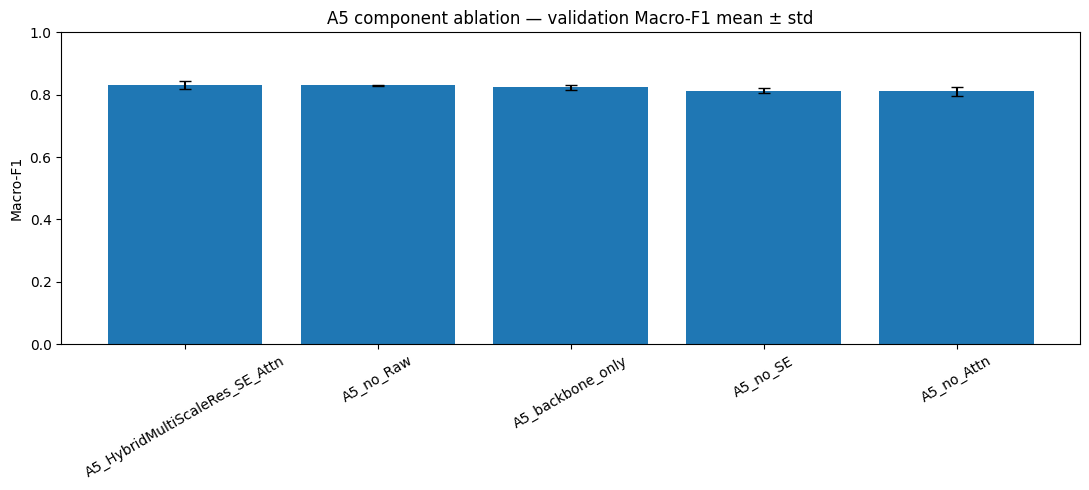

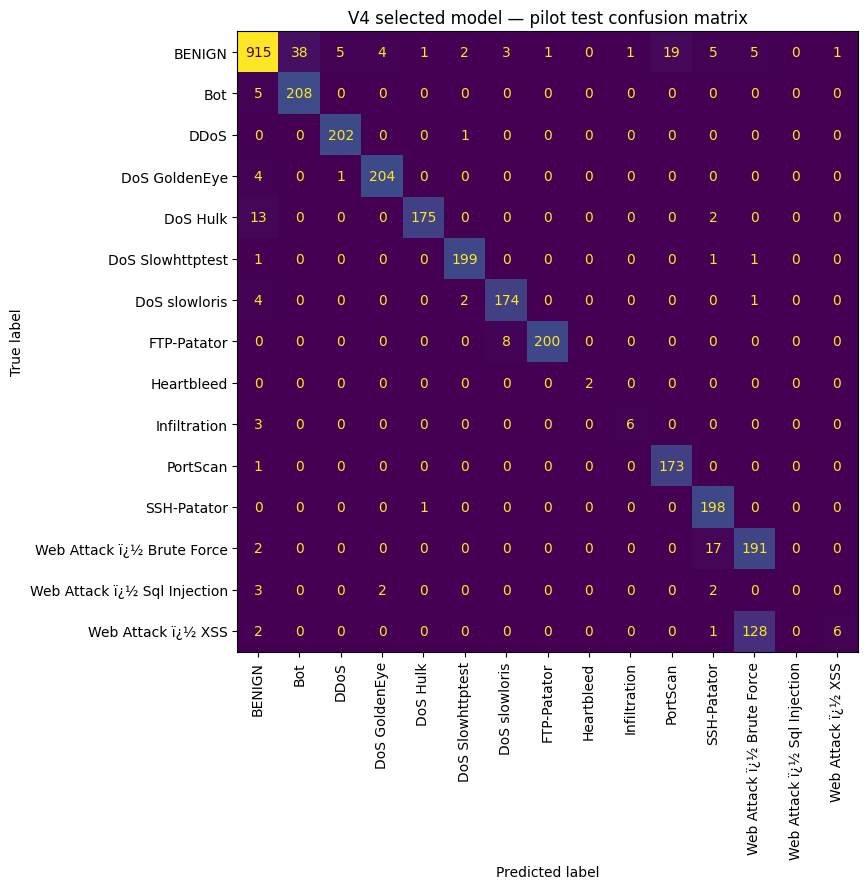

Outputs: /kaggle/working/nids_outputs/05_CNN_Ablation_V4_Targeted
ablation_summary.csv
ablation_trials.csv
ablation_validation_mean_std.png
experiment_manifest.json
final_test_metrics.json
selected_preprocessing.joblib
selected_test_confusion_matrix.png
test_classification_report.json
test_confusion_matrix.npy
test_per_class_report.csv
test_predictions.csv
trials
validation_calibration_grid.csv
validation_selection.json


In [71]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig,ax=plt.subplots(figsize=(11,5))
order=summary.sort_values('val_macro_f1_mean',ascending=False)
ax.bar(order['arch'],order['val_macro_f1_mean'],yerr=order['val_macro_f1_std'],capsize=4)
ax.set_title('A5 component ablation — validation Macro-F1 mean ± std')
ax.set_ylabel('Macro-F1');ax.set_ylim(0,1)
ax.tick_params(axis='x',rotation=30)
plt.tight_layout();fig.savefig(OUTPUT/'ablation_validation_mean_std.png',dpi=170);plt.show()
fig,ax=plt.subplots(figsize=(11,9))
ConfusionMatrixDisplay.from_predictions(y_test,final_pred,labels=class_ids,
    display_labels=encoder.classes_,xticks_rotation=90,ax=ax,colorbar=False)
ax.set_title('V4 selected model — pilot test confusion matrix')
plt.tight_layout();fig.savefig(OUTPUT/'selected_test_confusion_matrix.png',dpi=170);plt.show()

per_class=pd.DataFrame(report).T
per_class.to_csv(OUTPUT/'test_per_class_report.csv')
manifest={'search_mode':SEARCH_MODE,'budget':BUDGET,'seed':SEED,
  'fpr_target':FPR_TARGET,'bias_grid':BIAS_GRID,'features':features,
  'labels':encoder.classes_.tolist(),'split_sha256':sha,
  'selected_model':selected,'torch':torch.__version__,
  'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
  'notes':'Pilot only. V4 does not train genuine temporal models.'}
(OUTPUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
print('Outputs:',OUTPUT)
for p in sorted(OUTPUT.iterdir()):print(p.name)
